In [9]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import ticker
import math
from netCDF4 import Dataset

import warnings
warnings.filterwarnings("ignore")

In [10]:
# Constantes físicas
P0        = 1.0e5     # Presión base en Pa
R_earth   = 6360e3    # Radio terrestre en m
Gravity   = 9.806     # Aceleración de la gravedad en m/s²
R_gas     = 286.99    # Constante del gas ideal en J/kg.K
MW_dryair = 28.97     # Masa molecular del aire seco en g/mol
NA        = 6.022e23  # Número de Avogadro
deg2rad   = np.pi/180 # Conversión grados → radianes

def cargar_dataset(archivo):
    global data, lat, lon, hyam, hybm, hyai, hybi, temp, ps, tropp
    global nlat, nlon, nz, dlat, dlon
    global area, p, dp, dz, rho, volume
    global convertor, convertor2, convertor3
    global dataset_flag, molecules_cm3, rate_molec_cm3_s

    data = Dataset(archivo)

    lat  = data.variables['lat'][:].data
    lon  = data.variables['lon'][:].data
    hyam = data.variables['hyam'][:].data
    hybm = data.variables['hybm'][:].data
    hyai = data.variables['hyai'][:].data
    hybi = data.variables['hybi'][:].data

    temp = data.variables['T'][:].data[0]
    ps   = data.variables['PS'][:].data[0]
    tropp = data.variables['TROP_P'][:].data[0]

    nlat = lat.shape[0]
    nlon = lon.shape[0]
    nz   = hyam.shape[0]

    dlat = lat[1] - lat[0]
    dlon = lon[1] - lon[0]

    p = np.zeros([nz, nlat, nlon])
    for i in range(nz):
        p[i,:,:] = P0 * hyam[i] + hybm[i] * ps

    dp = np.zeros([nz, nlat, nlon])
    for i in range(nz):
        dp[i,:,:] = P0*(hyai[i+1] - hyai[i]) + (hybi[i+1] - hybi[i])*ps

    rho = p / (R_gas * temp)
    dz = dp / (rho * Gravity)

    dlat_rad = dlat * deg2rad
    dlon_rad = dlon * deg2rad
    area = np.zeros([nlat, nlon])
    for j in range(nlat):
        lat1 = (lat[j] - dlat/2) * deg2rad
        lat2 = (lat[j] + dlat/2) * deg2rad
        area[j,:] = (R_earth**2) * dlon_rad * (np.sin(lat2) - np.sin(lat1))

    volume = np.zeros([nz, nlat, nlon])
    for i in range(nz):
        volume[i,:,:] = dz[i,:,:] * area

    convertor = volume * 1e6
    convertor2 = area * NA * 1e3
    dz_surface = dz[0,:,:] 
    rate_molec_cm3_s = (NA) * 1e3/ (dz_surface * 1e6) 

    kB = 1.380649e-23  
    air_number_density = p / (kB * temp)   
    molecules_cm3 = air_number_density / 1e6 
    convertor3 = dp / Gravity

    dataset_flag = True

In [11]:
# Pesos atómicos
AW_Cl =  35.5
AW_Br =  79.9
AW_I  = 126.9
AW_H  =   1.0
AW_O  =  16.0
AW_N  =  14.0
AW_C  =  12.0
AW_F  =  19.0

# Pesos moleculares
MW_O3      = 3 * AW_O
MW_CHBR3   = AW_C + AW_H + 3 * AW_Br
MW_CH2BR2  = AW_C + 2 * AW_H + 2 * AW_Br
MW_CH2BRCL = AW_C + 2 * AW_H + AW_Br + AW_Cl
MW_CHBR2CL = AW_C + AW_H + 2*AW_Br + AW_Cl
MW_CHBRCL2 = AW_C + AW_H + AW_Br + 2 * AW_Cl
MW_CH2IBR  = AW_C + 2 * AW_H + AW_I + AW_Br
MW_CH2ICL  = AW_C + 2 * AW_H + AW_I + AW_Cl
MW_CH3I    = AW_C + 3 * AW_H + AW_I
MW_CH2I2   = AW_C + 2 * AW_H + 2 * AW_I
MW_BR2     = 2* AW_Br
MW_BRCL    = AW_Br + AW_Cl
MW_BRNO2   = AW_Br + AW_N + 2*AW_O
MW_BRONO2  = AW_Br + AW_N + 3*AW_O
MW_CLNO2   = AW_Cl + AW_N + 2*AW_O
MW_CLONO2  = AW_Cl + AW_N + 3*AW_O
MW_HCL     = AW_H + AW_Cl
MW_HBR     = AW_H + AW_Br
MW_HI      = AW_H + AW_I
MW_HOBR    = AW_H + AW_O + AW_Br
MW_HOCL    = AW_H + AW_O + AW_Cl
MW_HOI     = AW_H + AW_O + AW_I
MW_IBR     = AW_I + AW_Br
MW_I2O2    = 2 * AW_I + 2 * AW_O
MW_I2O3    = 2 * AW_I + 3 * AW_O
MW_I2O4    = 2 * AW_I + 4 * AW_O
MW_ICL     = AW_I + AW_Cl
MW_CL2     = 2 * AW_Cl
MW_INO2    = AW_I + AW_N + 2*AW_O
MW_IONO2   = AW_I + AW_N + 3*AW_O
MW_I2      = 2*AW_I
MW_IO      = AW_I + AW_O
MW_OIO     = AW_I + 2*AW_O
MW_CH3BR   = AW_C + 3*AW_H + AW_Br
MW_CF3BR   = AW_C + 3*AW_F + AW_Br
MW_CF2CLBR = AW_C + 2*AW_F + AW_Cl + AW_Br
MW_CH3CL   = AW_C + 3*AW_H + AW_Cl
MW_CCL4    = AW_C + 4*AW_Cl  
MW_CH3CCL3 = 2*AW_C + 3*AW_H + 3*AW_Cl 
MW_CFCL3   = AW_C + AW_F + 3*AW_Cl
MW_CF2CL2  = AW_C + 2*AW_F + 2*AW_Cl
MW_CF2BR2  = AW_C + 2*AW_F + 2*AW_Br     
MW_C2F4BR2 = 2*AW_C + 4*AW_F + 2*AW_Br 
MW_CH2CL2  = AW_C + 2*AW_H + 2*AW_Cl
MW_CHCL3   = AW_C + AW_H + 3*AW_Cl
MW_C2CL4   = 2*AW_C + 4*AW_Cl
MW_C2H4CL2 = 2*AW_C + 4*AW_H + 2*AW_Cl
MW_CHCL2O2 = AW_C + AW_H + 2*AW_Cl + 2*AW_O
MW_COFCL   = AW_C + AW_O + AW_F + AW_Cl
MW_COCL2   = AW_C + AW_O + 2*AW_Cl

In [12]:
folder = "./" 
file = "FC.f19_f19_mg17.L32.cesm2.2-asdbranch_slh_released.FCnudged_slh.Historic_SLH.cam.h0.2020-00.nc"

cargar_dataset(folder + file)

# Cargar las variables de sumideros del NetCDF

folder = "./"
file = "FC.f19_f19_mg17.L32.cesm2.2-asdbranch_slh_released.FCnudged_slh.Historic_SLH.cam.h0.2020-00.nc"
cargar_dataset(folder + file)

# Cloruros (Sinks)
dtwr_hcl = data.variables["DTWR_HCL"][0]
dtwr_clno2 = data.variables["DTWR_CLNO2"][0]
dtwr_hocl = data.variables["DTWR_HOCL"][0]
dtwr_clono2 = data.variables["DTWR_CLONO2"][0]
dtwr_brcl = data.variables["DTWR_BRCL"][0]
dtwr_icl = data.variables["DTWR_ICL"][0]

# Bromuros (Sinks)
dtwr_hobr = data.variables["DTWR_HOBR"][0]
dtwr_hbr = data.variables["DTWR_HBR"][0]
dtwr_brno2 = data.variables["DTWR_BRNO2"][0]
dtwr_brono2 = data.variables["DTWR_BRONO2"][0]
dtwr_br2 = data.variables["DTWR_BR2"][0]
dtwr_ibr = data.variables["DTWR_IBR"][0]

md_hbr = data.variables["DF_HBR"][0]
md_br2 = data.variables["DF_BR2"][0]
md_brno2 = data.variables["DF_BRNO2"][0]
md_brono2 = data.variables["DF_BRONO2"][0]
md_hobr = data.variables["DF_HOBR"][0]

# Yoduros (Sinks)
dtwr_hi = data.variables['DTWR_HI'][0]
dtwr_i2o2 = data.variables["DTWR_I2O2"][0]
dtwr_i2o3 = data.variables["DTWR_I2O3"][0]
dtwr_i2o4 = data.variables["DTWR_I2O4"][0]
dtwr_ino2 = data.variables["DTWR_INO2"][0]
dtwr_io = data.variables["DTWR_IO"][0]
dtwr_iono2 = data.variables["DTWR_INO2"][0]
dtwr_oio = data.variables["DTWR_OIO"][0]

df_hi = data.variables["DF_HI"][0]
df_hoi = data.variables["DF_HOI"][0]
df_i2o2 = data.variables["DF_I2O2"][0]
df_i2o3 = data.variables["DF_I2O3"][0]
df_i2o4 = data.variables["DF_I2O4"][0]
df_ino2 = data.variables["DF_INO2"][0]
df_iono2 = data.variables["DF_IONO2"][0]

# Inicialización y asignación de arreglos
fot_chbr3 = np.zeros([1,32,96,144])
fot_ch2br2 = np.zeros([1,32,96,144])
fot_ch2brcl = np.zeros([1,32,96,144])
fot_chbr2cl = np.zeros([1,32,96,144])
fot_chbrcl2  = np.zeros([1,32,96,144])
fot_ch2ibr = np.zeros([1,32,96,144])
fot_ch3br = np.zeros([1,32,96,144])
fot_cf3br = np.zeros([1,32,96,144])
fot_cf2clbr = np.zeros([1,32,96,144])
#fot_cf2br2 = np.zeros([year_count,12,26,96,144])
#fot_c2f4br2 = np.zeros([year_count,12,26,96,144])
#fot_h1202 =  np.zeros([year_count,12,32,96,144])
fot_h2402 =  np.zeros([1,32,96,144])

#'h1202', 'h2402
oh_chbr3 = np.zeros([1,32,96,144])
oh_ch2br2 = np.zeros([1,32,96,144])
oh_ch2brcl = np.zeros([1,32,96,144])
oh_chbr2cl = np.zeros([1,32,96,144])
oh_chbrcl2 = np.zeros([1,32,96,144])
oh_ch3br = np.zeros([1,32,96,144])

o1d_chbr3  = np.zeros([1,32,96,144])
o1d_ch2br2 = np.zeros([1,32,96,144])
cl_chbr3  = np.zeros([1,32,96,144])
cl_ch2br2 = np.zeros([1,32,96,144])
cl_ch3br = np.zeros([1,32,96,144])
o1d_ch3br = np.zeros([1,32,96,144])
o1d_cf3br = np.zeros([1,32,96,144])
o1d_cof2  = np.zeros([1,32,96,144])
o1d_h2402  = np.zeros([1,32,96,144])


r_het_ss_0 = np.zeros([1,32,96,144])
r_het_ss_1 = np.zeros([1,32,96,144])
r_het_ss_2 = np.zeros([1,32,96,144])
r_het_ss_3 = np.zeros([1,32,96,144])
r_het_ss_4 = np.zeros([1,32,96,144])
r_het_ss_5 = np.zeros([1,32,96,144])
r_het_ss_6 = np.zeros([1,32,96,144])
r_het_ss_7 = np.zeros([1,32,96,144])
r_het_ss_8 = np.zeros([1,32,96,144])
broy = np.zeros([1,32,96,144])


#cloruros
cloy = np.zeros([1,32,96,144])
fot_ch2icl = np.zeros([1,32,96,144])
#'hocl',  'brcl',  'icl',  'hcl',  'clno2',  'clono2'
#ch3cl',  'ccl4',  'ch3ccl3',  'cfcl3', 'cf2cl2', 'cf2clbr'
fot_chcl3 = np.zeros([1,32,96,144])
oh_chcl3 = np.zeros([1,32,96,144])
cl_chcl3 = np.zeros([1,32,96,144])
fot_c2cl4 = np.zeros([1,32,96,144])
oh_c2cl4 = np.zeros([1,32,96,144])
cl_M_c2cl4 = np.zeros([1,32,96,144])
fot_cf2cl2 = np.zeros([1,32,96,144])
oh_ch3ccl3 = np.zeros([1,32,96,144])
r_het_ss_12 = np.zeros([1,32,96,144])
r_het_ss_9 = np.zeros([1,32,96,144])
r_het_ss_99 = np.zeros([1,32,96,144])
fot_ch2cl2 = np.zeros([1,32,96,144])
oh_ch2cl2 = np.zeros([1,32,96,144])
cl_ch2cl2 = np.zeros([1,32,96,144])
fot_c2h4cl2 = np.zeros([1,32,96,144])
oh_c2h4cl2 = np.zeros([1,32,96,144])
cl_c2h4cl2 = np.zeros([1,32,96,144])
brcl = np.zeros([1,32,96,144])

fot_cf2clbr = np.zeros([1,32,96,144])
o1d_cf2clbr = np.zeros([1,32,96,144])
fot_ccl4 = np.zeros([1,32,96,144])
o1d_ccl4 = np.zeros([1,32,96,144])
fot_cfcl3 = np.zeros([1,32,96,144])
o1d_cfcl3 = np.zeros([1,32,96,144])
fot_cfc113 = np.zeros([1,32,96,144])
o1d_cfc113 = np.zeros([1,32,96,144])
fot_cfc114 = np.zeros([1,32,96,144])
o1d_cfc114 = np.zeros([1,32,96,144])
fot_cfc115 = np.zeros([1,32,96,144])
o1d_cfc115 = np.zeros([1,32,96,144])
fot_cf2cl2 = np.zeros([1,32,96,144])
o1d_cfc12 = np.zeros([1,32,96,144])
fot_ch3ccl3 = np.zeros([1,32,96,144])
o1d_ch3ccl3 = np.zeros([1,32,96,144])
fot_ch3cl = np.zeros([1,32,96,144])
oh_ch3cl = np.zeros([1,32,96,144])
cl_ch3cl = np.zeros([1,32,96,144])
fot_hcfc141b = np.zeros([1,32,96,144])
oh_hcfc141b = np.zeros([1,32,96,144])
o1d_hcfc141b = np.zeros([1,32,96,144])
fot_hcfc142b = np.zeros([1,32,96,144])
oh_hcfc142b = np.zeros([1,32,96,144])
o1d_hcfc142b = np.zeros([1,32,96,144])
fot_hcfc22 = np.zeros([1,32,96,144])
o1d_hcfc22 = np.zeros([1,32,96,144])
oh_hcfc22 = np.zeros([1,32,96,144])


#ioduros
#'ch2icl',  'ch3i',  'ch2ibr',  'ch2i2'
#'hi',   'i2o2',   'i2o3',   'i2o4',  'ibr',   'icl',   'ino2',  'io', 
#'iono2',  'oio
fot_ch3i  = np.zeros([1,32,96,144])
fot_ch2i2 = np.zeros([1,32,96,144])
oh_ch3i = np.zeros([1,32,96,144])
cl_ch3i = np.zeros([1,32,96,144]) #
r_liq_fr_hoi = np.zeros([1,32,96,144])
r_ice_fr_hi = np.zeros([1,32,96,144])
r_ice_fr_hoi = np.zeros([1,32,96,144])
r_ice_fr_iono2 = np.zeros([1,32,96,144])
ioy = np.zeros([1,32,96,144])

cl  = np.zeros([1,32,96,144])
clo = np.zeros([1,32,96,144])
hcl = np.zeros([1,32,96,144])
hocl = np.zeros([1,32,96,144]) 
clono2 = np.zeros([1,32,96,144])
clno2 = np.zeros([1,32,96,144])
cl2 = np.zeros([1,32,96,144])
cly = np.zeros([1,32,96,144])

br  = np.zeros([1,32,96,144])
bro = np.zeros([1,32,96,144])
hbr = np.zeros([1,32,96,144])
hobr = np.zeros([1,32,96,144]) 
brono2 = np.zeros([1,32,96,144])
brno2 = np.zeros([1,32,96,144])
br2 = np.zeros([1,32,96,144])
bry = np.zeros([1,32,96,144])

i_  = np.zeros([1,32,96,144])
io = np.zeros([1,32,96,144])
hi = np.zeros([1,32,96,144])
hoi = np.zeros([1,32,96,144]) 
iono2 = np.zeros([1,32,96,144])
ino2 = np.zeros([1,32,96,144])
i2 = np.zeros([1,32,96,144])
iy = np.zeros([1,32,96,144])

cloy_sums = np.zeros([1,32,96,144])
broy_sums = np.zeros([1,32,96,144])
ioy_sums = np.zeros([1,32,96,144])

chcl2o2= np.zeros([1,32,96,144])
cofcl = np.zeros([1,32,96,144])
cocl2 = np.zeros([1,32,96,144])
cl2o2 = np.zeros([1,32,96,144])
oclo = np.zeros([1,32,96,144])
brcl = np.zeros([1,32,96,144])
icl = np.zeros([1,32,96,144])
ibr = np.zeros([1,32,96,144])

#oddox

OddOx_BROx_Loss = np.zeros([1,32,96,144])
OddOx_CLOxBROx_Loss = np.zeros([1,32,96,144])
OddOx_CLOx_Loss = np.zeros([1,32,96,144])
OddOx_HOx_Loss = np.zeros([1,32,96,144])
OddOx_IOx_Loss = np.zeros([1,32,96,144])
OddOx_Loss_Tot = np.zeros([1,32,96,144])
OddOx_NOx_Loss = np.zeros([1,32,96,144])
OddOx_Ox_Loss = np.zeros([1,32,96,144])
OddOx_Prod_Tot = np.zeros([1,32,96,144])
ocean_hoi = np.zeros([1,32,96,144])
ocean_i2 = np.zeros([1,32,96,144])




folder = "./"
file = "FC.f19_f19_mg17.L32.cesm2.2-asdbranch_slh_released.FCnudged_slh.Historic_SLH.cam.h0.2020-00.nc"
cargar_dataset(folder + file)

#print(file)
fot_chbr3  = data.variables['r_jchbr3'][0]
fot_ch2br2 = data.variables['r_jch2br2'][0]
fot_ch2brcl  = data.variables['r_jch2brcl'][0]
fot_chbr2cl = data.variables['r_jchbr2cl'][0]
fot_chbrcl2  = data.variables['r_jchbrcl2'][0]
fot_ch2ibr = data.variables['r_jch2ibr'][0]
fot_h2402 = data.variables['r_jh2402'][0]
fot_ch3br = data.variables['r_jch3br'][0]
fot_cf3br  = data.variables['r_jcf3br'][0]
fot_cf2clbr = data.variables['r_jcf2clbr'][0]
fot_ch2ibr = data.variables['H2402'][0]
oh_chbr3 = data.variables['r_CHBR3_OH'][0]
oh_ch2br2 = data.variables['r_CH2BR2_OH'][0]
oh_ch2brcl = data.variables['r_CH2BRCL_OH'][0]
oh_chbr2cl = data.variables['r_CHBR2CL_OH'][0]
oh_chbrcl2 = data.variables['r_CHBRCL2_OH'][0]
oh_ch3br = data.variables['r_CH3BR_OH'][0]
o1d_chbr3 = data.variables['r_O1D_CHBR3'][0]
o1d_ch2br2 = data.variables['r_O1D_CH2BR2'][0]
cl_chbr3 = data.variables['r_CHBR3_CL'][0]
cl_ch2br2 = data.variables['r_CH2BR2_CL'][0]
cl_ch3br = data.variables['r_CH3BR_CL'][0]
o1d_ch3br = data.variables['r_O1D_CH3BR'][0]
o1d_cf3br = data.variables['r_O1D_CF3BR'][0]
o1d_h2402 = data.variables['r_O1D_H2402'][0]
brcl = data.variables['BRCL'][0]
#o1d_ch3ccl3 = data.variables['r_O1D_CH3CCL3'][0]

r_het_ss_0 = data.variables['r_het_ss_0'][0]
r_het_ss_1 = data.variables['r_het_ss_1'][0]
r_het_ss_2 = data.variables['r_het_ss_2'][0]
r_het_ss_3 = data.variables['r_het_ss_3'][0]
r_het_ss_4 = data.variables['r_het_ss_4'][0]
r_het_ss_5 = data.variables['r_het_ss_5'][0]
r_het_ss_6 = data.variables['r_het_ss_6'][0]
r_het_ss_7 = data.variables['r_het_ss_7'][0]
r_het_ss_8 = data.variables['r_het_ss_8'][0]
r_het_ss_12 = data.variables['r_het_ss_12'][0]
r_het_ss_9 = data.variables['r_het_ss_9'][0]
broy = data.variables['BROY'][0]

#cloruros hocl',  'brcl',  'icl',  'hcl',  'clno2',  'clono2', 'cl2'
cloy = data.variables['CLOY'][0]

fot_ch3cl = data.variables["r_jch3cl"][0]
fot_ccl4 = data.variables["r_jccl4"][0]
fot_ch3ccl3 = data.variables["r_jch3ccl3"][0]
fot_cfcl3 = data.variables["r_jcfcl3"][0]
fot_cf2cl2 = data.variables["r_jcf2cl2"][0]
fot_cf2clbr = data.variables["r_jcf2clbr"][0]
fot_chcl3 = data.variables["r_jchcl3"][0]
fot_c2cl4 = data.variables["r_jc2cl4"][0]
fot_ch2cl2 = data.variables["r_jch2cl2"][0]
fot_c2h4cl2 = data.variables["r_jc2h4cl2"][0]
fot_cfc113 = data.variables["r_jcfc113"][0]
fot_cfc114 = data.variables["r_jcfc114"][0]
fot_cfc115 = data.variables["r_jcfc115"][0]
fot_hcfc141b = data.variables["r_jhcfc141b"][0]
fot_hcfc142b = data.variables["r_jhcfc142b"][0]
fot_hcfc22 = data.variables["r_jhcfc22"][0]
oh_hcfc142b = data.variables["r_HCFC142B_OH"][0]
fot_ch2icl = data.variables["r_jch2icl"][0]

oh_ch3cl = data.variables["r_CH3CL_OH"][0]
oh_ch3ccl3 = data.variables["r_CH3CCL3_OH"][0]
oh_chcl3 = data.variables["r_CHCL3_OH"][0]
oh_ch2cl2 = data.variables["r_CH2CL2_OH"][0]
oh_c2cl4 = data.variables["r_C2CL4_OH"][0]
oh_c2h4cl2 = data.variables["r_C2H4CL2_OH"][0]
oh_hcfc141b = data.variables["r_HCFC141B_OH"][0]
oh_hcfc22 = data.variables["r_HCFC22_OH"][0]

cl_M_c2cl4 = data.variables["r_C2CL4_CL_M"][0]
cl_ch2cl2 = data.variables["r_CH2CL2_CL"][0]
cl_chcl3 = data.variables["r_CHCL3_CL"][0]
cl_c2h4cl2 = data.variables["r_C2H4CL2_CL"][0]
cl_ch3cl = data.variables["r_CH3CL_CL"][0]

o1d_cf2clbr = data.variables["r_O1D_CF2CLBR"][0]
o1d_ccl4 = data.variables["r_O1D_CCL4"][0]
o1d_cfcl3 = data.variables["r_O1D_CFC11"][0]
o1d_cfc113 = data.variables["r_O1D_CFC113"][0]
o1d_cfc114 = data.variables["r_O1D_CFC114"][0]
o1d_cfc115 = data.variables["r_O1D_CFC115"][0]
o1d_cfc12 = data.variables["r_O1D_CFC12"][0]
o1d_hcfc141b = data.variables["r_O1D_HCFC141B"][0]
o1d_hcfc142b = data.variables["r_O1D_HCFC142B"][0]
o1d_hcfc22 = data.variables["r_O1D_HCFC22"][0]


#ioduros

fot_ch3i = data.variables['r_jch3i'][0]
oh_ch3i = data.variables['r_CH3I_OH'][0]
fot_ch2i2 = data.variables['r_jch2i2'][0]
cl_ch3i = data.variables['r_CH3I_CL'][0]#

r_liq_fr_hoi = data.variables['r_liq_fr_hoi'][0]
r_ice_fr_hi = data.variables['r_ice_fr_hi'][0]
r_ice_fr_hoi = data.variables['r_ice_fr_hoi'][0]
r_ice_fr_iono2 = data.variables['r_ice_fr_iono2'][0]
ioy = data.variables['IOY'][0]


cl = data.variables["CL"][0]
clo = data.variables["CLO"][0]
hcl = data.variables["HCL"][0]
hocl = data.variables["HOCL"][0]
clono2 = data.variables["CLONO2"][0]
clno2 = data.variables["CLNO2"][0]
cl2 = data.variables["CL2"][0]
#cly = data.variables["CLY"][0]

br = data.variables["BR"][0]
bro = data.variables["BRO"][0]
hbr = data.variables["HBR"][0]
hobr = data.variables["HOBR"][0]
brono2 = data.variables["BRONO2"][0]
brno2 = data.variables["BRNO2"][0]
br2 = data.variables["BR2"][0]
#bry = data.variables["BRY"][0]

i_ = data.variables["I"][0]
io = data.variables["IO"][0]
hi = data.variables["HI"][0]
hoi = data.variables["HOI"][0]
iono2 = data.variables["IONO2"][0]
ino2 = data.variables["INO2"][0]
i2 = data.variables["I2"][0]

cloy_sums = data.variables["CLOy_sums"][0]
broy_sums = data.variables["BROy_sums"][0]
ioy_sums = data.variables["IOy_sums"][0]

chcl2o2 = data.variables["CHCL2O2"][0]
cofcl = data.variables["COFCL"][0]
cocl2 = data.variables["COCL2"][0]

cl2o2 = data.variables["CL2O2"][0]
oclo = data.variables["OCLO"][0]
brcl = data.variables["BRCL"][0]
icl = data.variables["ICL"][0]
ibr = data.variables["IBR"][0]

#------------------------------------------------
OddOx_BROx_Loss = data.variables["OddOx_BROx_Loss"][0]
OddOx_CLOxBROx_Loss = data.variables["OddOx_CLOxBROx_Loss"][0]

OddOx_CLOx_Loss = data.variables["OddOx_CLOx_Loss"][0]
OddOx_HOx_Loss = data.variables["OddOx_HOx_Loss"][0]
OddOx_IOx_Loss = data.variables["OddOx_IOx_Loss"][0]

OddOx_Loss_Tot = data.variables["OddOx_Loss_Tot"][0]
OddOx_NOx_Loss = data.variables["OddOx_NOx_Loss"][0]
OddOx_Ox_Loss = data.variables["OddOx_Ox_Loss"][0]
OddOx_Prod_Tot = data.variables["OddOx_Prod_Tot"][0]
ocean_hoi = data.variables['SFHOI'][0]
ocean_i2 = data.variables['SFI2'][0]


In [13]:
# Bromo
bryy =  br + bro + hbr + hobr + brono2 + brno2 + 2*br2 + brcl + ibr
br_vmr = [br*1e12, bro*1e12, hbr*1e12, hobr*1e12, brcl*1e12, (brno2 + brono2)*1e12, (ibr + br2)*1e12, bryy*1e12]
color = ['#999933', "#AA4499", '#DDCC77', '#882255','#CC6677',"#117733", 'dodgerblue', 'black']
br_vmr_b = ['Br', 'BrO', 'HBr', 'HOBr', 'BrONO$_2$ + BrNO$_2$' , 'BrCl','Br$_2$ + IBr' , 'Br$_y$']

f_vsl = 3 * fot_chbr3 + 2 * fot_ch2br2 + fot_ch2brcl + 2 * fot_chbr2cl + fot_chbrcl2 + fot_ch2ibr 
oh_vsl = 3 * oh_chbr3 + 2 * oh_ch2br2 + oh_ch2brcl + 2 * oh_chbr2cl + oh_chbrcl2 
cl_vsl = 3 * cl_chbr3 + 2 * cl_ch2br2
o1d_vsl = 3 * o1d_chbr3 + 2 * o1d_ch2br2
vsl = f_vsl + oh_vsl + cl_vsl + o1d_vsl
f_ll =  2 * fot_h2402 + fot_cf3br + fot_cf2clbr  
o1d_ll = o1d_cf3br + o1d_cf2clbr 
ll = f_ll + o1d_ll
ll_ch3br = fot_ch3br + oh_ch3br + cl_ch3br + o1d_ch3br
h = 0.65 * (r_het_ss_0 + r_het_ss_1 + r_het_ss_2) + 0.5 * (r_het_ss_6 + r_het_ss_7 + r_het_ss_8)
c = [vsl, ll, ll_ch3br, h] 

b = ["Br$_y$ from VSL", "Br$_y$ from LLH", "Br$_y$ from CH$_3$Br", "Br$_y$ from SSA"]
d = ["x", ".", "v", 'o']
v = ["#332288", "darkorange","#DDCC77", "#117733"]

# Cloro
clyy = cl + clo + hcl + hocl + clono2 + clno2 + 2*cl2 + 2*cl2o2 + oclo + brcl + icl
cl_vmr = [cl*1e12, clo*1e12, hcl*1e12, hocl*1e12, brcl*1e12, (clno2 + clono2)*1e12, (icl + cl2)*1e12, clyy*1e12]
cl_vmr_b = ['Cl', 'ClO', 'HCl', 'HOCl', 'ClONO$_2$ + ClNO$_2$' ,'BrCl', 'Cl$_2$ + ICl' , 'Cl$_y$']

cl_f_vsl_n = fot_ch2icl + fot_ch2brcl + fot_chbr2cl + 2 * fot_chbrcl2  
cl_oh_vsl_n =  oh_ch2brcl +  oh_chbr2cl + 2 * oh_chbrcl2 
cl_vsl_n = cl_oh_vsl_n + cl_f_vsl_n

cl_f_vsl_a = 2 * fot_ch2cl2 + 4*fot_c2cl4 + 3*fot_chcl3 + 2*fot_c2h4cl2
cl_oh_vsl_a = 2 * oh_ch2cl2 + 4*oh_c2cl4 + 3*oh_chcl3 + 2*oh_c2h4cl2
cl_cl_a = 2 * cl_ch2cl2  + 3*cl_chcl3 + 2*cl_c2h4cl2 + 4*cl_M_c2cl4
cl_vsl_a = cl_f_vsl_a + cl_oh_vsl_a + cl_cl_a

cl_f_ll = 2 * fot_cf2cl2 + fot_cf2clbr + 4*fot_ccl4 + 3 *fot_cfcl3 + 3* fot_cfc113 + 2*fot_cfc114 + fot_cfc115 + 3*fot_ch3ccl3 + 2 * fot_hcfc141b + fot_hcfc142b + fot_hcfc22
cl_oh_ll =  3 * oh_ch3ccl3 + 2 * oh_hcfc141b + oh_hcfc142b + oh_hcfc22
cl_o1d_ll = o1d_cf2clbr + 4 * o1d_ccl4 + 3 * o1d_cfcl3 + 3 * o1d_cfc113 + 2* o1d_cfc114 + o1d_cfc115 + 2*o1d_cfc12 + 2*o1d_hcfc141b + o1d_hcfc142b + o1d_hcfc22
cl_ll = cl_f_ll + cl_oh_ll + cl_o1d_ll
cl_ll_ch3cl = fot_ch3cl + oh_ch3cl + cl_ch3cl

cl_h = 0.35 * (r_het_ss_0 + r_het_ss_1 + r_het_ss_2) + 1.0 * (r_het_ss_3 + r_het_ss_4 + r_het_ss_5) + 0.5 * (r_het_ss_6 + r_het_ss_7 + r_het_ss_8) 
cl_p = 1.0 * (r_het_ss_12 + r_het_ss_9)
cl_c = [cl_vsl_n, cl_vsl_a, cl_ll, cl_ll_ch3cl, cl_h, cl_p]

cl_b = ["Cl$_y$ from VSL NAT", "Cl$_y$ from VSL Anthrop",  "Cl$_y$ from LLH ", "Cl$_y$ from CH$_3$Cl ", "Cl$_y$ from SSA Hal", "Cl$_y$ from SSA Acids"]
cl_v = ["#332288", "black", "darkorange", "#DDCC77", "#117733" , "#44AA99"]

# Yodo
iyy = i_ + io + hi + hoi + iono2 + ino2 + 2*i2
i_vmr = [i_*1e12, io*1e12, hi*1e12, hoi*1e12, (ino2 + iono2)*1e12, (i2 + ibr + icl)*1e12, iyy*1e12]
i_color = ['#999933', "#AA4499", '#DDCC77', '#882255', '#CC6677', 'dodgerblue', 'black']
i_vmr_b = ['I', 'IO', 'HI', 'HOI', 'IONO$_2$ + INO$_2$' , ' I$_2$ + ICl +IBr','I$_y$']

i_f_vsl = fot_ch2icl + fot_ch2ibr + 2 * fot_ch2i2
i_vsl_ch3i = fot_ch3i + cl_ch3i + oh_ch3i
i_vsl = i_f_vsl 
ocean = (ocean_hoi*rate_molec_cm3_s*3e1 / MW_HOI) + (2*ocean_i2*rate_molec_cm3_s*3e1/ MW_I2)
i_c = [i_vsl, i_vsl_ch3i]

i_b = ["I$_y$ from VSLs minors", "I$_y$ from CH$_3$I"]
i_v = ["#332288", "cyan"]

In [23]:
# =========================================
# 1. CÁLCULO DE SUMIDEROS PARA Cl_y, Br_y e I_y
# =========================================

# --- A. Cloruros (Cl_y) ---
dtwr_ress = -MW_dryair / 1e-12 * 86000 * (
    (1/MW_HCL) * dtwr_hcl + 
    (1/MW_CLNO2) * dtwr_clno2 + 
    (1/MW_HOCL) * dtwr_hocl + 
    (1/MW_CLONO2) * dtwr_clono2
)

# --- B. Bromuros (Br_y) ---
dtwr_res = -MW_dryair / 1e-12 * 86000 * (
    (1/MW_HOBR) * dtwr_hobr + 
    (1/MW_HBR) * dtwr_hbr + 
    (2/MW_BRNO2) * dtwr_brno2 + 
    (2/MW_BRONO2) * dtwr_brono2
)

# Deposición seca de bromo (superficie)
md = (
    (2 * md_br2 * Gravity / dp[0,:,:] / MW_BR2) +
    (md_hobr * Gravity / dp[0,:,:] / MW_HOBR) +
    (md_hbr * Gravity / dp[0,:,:] / MW_HBR) +
    (md_brno2 * Gravity / dp[0,:,:] / MW_BRNO2) +
    (md_brono2 * Gravity / dp[0,:,:] / MW_BRONO2)
)
md_pptv_day = md * MW_dryair * 1e12 * 86400  

# --- C. Yoduros (I_y) ---
df_hi = data.variables["DF_HI"][0]
df_hoi = data.variables["DF_HOI"][0]
df_i2o2 = data.variables["DF_I2O2"][0]
df_i2o3 = data.variables["DF_I2O3"][0]
df_i2o4 = data.variables["DF_I2O4"][0]
df_ino2 = data.variables["DF_INO2"][0]
df_iono2 = data.variables["DF_IONO2"][0]

dtwr_i_res = np.abs(-MW_dryair / 1e-12 * 86000 * (
    (1 / MW_HI) * dtwr_hi +
    (1 / MW_IONO2) * dtwr_iono2 +
    (1 / MW_INO2) * dtwr_ino2 +
    (1 / MW_IO) * dtwr_io +
    (1 / MW_OIO) * dtwr_oio +
    (2 / MW_I2O2) * dtwr_i2o2 +
    (2 / MW_I2O3) * dtwr_i2o3 +
    (2 / MW_I2O4) * dtwr_i2o4
))

md_i = (
    (df_hi * Gravity / dp[0,:,:] / MW_HI) +
    (df_hoi * Gravity / dp[0,:,:] / MW_HOI) +
    (2 * df_i2o2 * Gravity / dp[0,:,:] / MW_I2O2) +
    (2 * df_i2o3 * Gravity / dp[0,:,:] / MW_I2O3) +
    (2 * df_i2o4 * Gravity / dp[0,:,:] / MW_I2O4) +
    (df_ino2 * Gravity / dp[0,:,:] / MW_INO2) +
    (df_iono2 * Gravity / dp[0,:,:] / MW_IONO2)
)
md_i_pptv_day = md_i * MW_dryair * 1e12 * 86400

# Deposición Seca de Cloro
DF_HCL = data.variables["DF_HCL"][0]
DF_HOCL = data.variables["DF_HOCL"][0]
DF_CLONO2 = data.variables["DF_CLONO2"][0]
DF_CLNO2 = data.variables["DF_CLNO2"][0]
DF_COCL2 = data.variables["DF_COCL2"][0]

md_cl = (
    (DF_HCL * Gravity / dp[0,:,:] / MW_HCL) +
    (DF_HOCL * Gravity / dp[0,:,:] / MW_HOCL) +
    (DF_CLONO2 * Gravity / dp[0,:,:] / MW_CLONO2) +
    (DF_CLNO2 * Gravity / dp[0,:,:] / MW_CLNO2) +
    (DF_COCL2 * Gravity / dp[0,:,:] / MW_COCL2)
)
md_cl_pptv_day = md_cl * MW_dryair * 1e12 * 86400

# =========================================
r_liq_fr_hoi = data.variables['r_liq_fr_hoi'][0]
r_ice_fr_hi = data.variables['r_ice_fr_hi'][0]
r_ice_fr_hoi = data.variables['r_ice_fr_hoi'][0]
r_ice_fr_iono2 = data.variables['r_ice_fr_iono2'][0]

# CÁLCULO NORMALIZADO DE LOS "FRAS" DE YODO (ppt / mes)

seconds_per_month = 86400 * 30  # Segundos aproximados en un mes

# Dividimos por molecules_cm3 para normalizar la tasa absoluta por la densidad del aire
fra_i_tot = np.abs(
    (r_liq_fr_hoi / molecules_cm3 + 
     r_ice_fr_hoi / molecules_cm3 + 
     r_ice_fr_hi / molecules_cm3 + 
     r_ice_fr_iono2 / molecules_cm3)
) * 1e12 * seconds_per_month

print("Nuevo Mínimo fra_i_tot:", np.nanmin(fra_i_tot))
print("Nuevo Máximo fra_i_tot:", np.nanmax(fra_i_tot))

Nuevo Mínimo fra_i_tot: 0.0
Nuevo Máximo fra_i_tot: 496.4527367703428


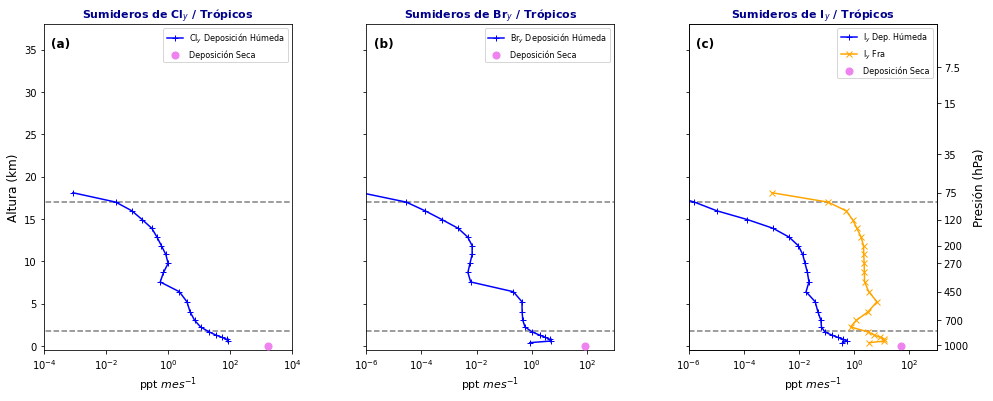

In [27]:
# Ploteo de los sumideros (Cl_y, Br_y, I_y)

H = [38.0217, 32.8987, 28.6571, 25.1301, 22.6889, 21.5085, 20.3665, 19.2606,
     18.1107, 17.0031, 15.9729, 14.942, 13.9116, 12.8814, 11.853, 10.826, 9.77737,
     8.69542, 7.5791, 6.42741, 5.23926, 4.03541, 3.05838, 2.27118, 1.68529, 1.30937,
     1.05048, 0.814904, 0.603055, 0.415288, 0.251906, 0.113291]
    
Pre = [3.5, 7.5, 15, 25, 35, 45, 50, 60, 75, 90, 100, 120, 140, 170, 200, 230, 270, 320, 380, 450, 520, 610, 700, 770, 825, 865, 900, 920, 940, 960, 980, 1000]
positions = np.array([0, 1, 2, 4, 8, 11, 14, 16, 19, 22, 31]) 
alturag = [H[i] for i in positions]
presg = [Pre[i] for i in positions]

fig, axes = plt.subplots(1, 3, figsize=(16, 6), sharey=True)
plt.subplots_adjust(wspace=0.3)

# 1. Gráfica de Cl_y (Deposición Húmeda + Seca de Cloro)
axes[0].plot(np.mean(dtwr_ress[:, 37:59, :], axis=(1,2))[8:29], H[8:29], label="Cl$_y$ Deposición Húmeda", color="blue", marker="+")
axes[0].scatter(np.nanmean(md_cl_pptv_day[37:59, :] if md_cl_pptv_day.ndim == 3 else md_cl_pptv_day), 0, color="violet", marker="o", s=50, zorder=10, label="Deposición Seca")
axes[0].set_xlim(1e-4, 1e4)
axes[0].set_title("Sumideros de Cl$_y$ / Trópicos", fontsize=11, fontweight='bold', color='darkblue')

# 2. Gráfica de Br_y (Deposición Húmeda + Seca de Bromo)
axes[1].plot(np.mean(dtwr_res[:, 37:59, :], axis=(1,2))[6:30], H[6:30], label="Br$_y$ Deposición Húmeda", color="blue", marker="+")
axes[1].scatter(np.nanmean(md_pptv_day[37:59, :] if md_pptv_day.ndim == 3 else md_pptv_day), 0, color="violet", marker="o", s=50, zorder=10, label="Deposición Seca")
axes[1].set_xlim(1e-6, 1e3)
axes[1].set_title("Sumideros de Br$_y$ / Trópicos", fontsize=11, fontweight='bold', color='darkblue')

# 3. Gráfica de I_y (Deposición Húmeda + Fras heterogéneos normalizados + Seca de Yodo)
axes[2].plot(np.mean(dtwr_i_res[:, 37:59, :], axis=(1,2))[6:30], H[6:30], label="I$_y$ Dep. Húmeda", color="blue", marker="+")

# Enmascaramos los ceros exactos para que no rompan la escala logarítmica
fra_plottable = np.ma.masked_equal(np.mean(fra_i_tot[:, 37:59, :], axis=(1,2))[6:30], 0.0)
axes[2].plot(fra_plottable, H[6:30], label="I$_y$ Fra", color="orange", marker="x")

axes[2].scatter(np.nanmean(md_i_pptv_day[37:59, :] if md_i_pptv_day.ndim == 3 else md_i_pptv_day), 0, color="violet", marker="o", s=50, zorder=10, label="Deposición Seca")
axes[2].set_xlim(1e-6, 1e3)
axes[2].set_title("Sumideros de I$_y$ / Trópicos", fontsize=11, fontweight='bold', color='darkblue')

# Configuraciones comunes para los subplots
for i, ax in enumerate(axes):
    ax.set_xscale("log")
    ax.set_ylim(-0.5, 38)
    ax.hlines(y=1.8, xmin=1e-6, xmax=1e4, ls="--", color='gray')
    ax.hlines(y=17, xmin=1e-6, xmax=1e4, ls="--", color='gray')  
    ax.set_xlabel(r'ppt $mes^{-1}$', fontsize=11)
    ax.legend(loc='upper right', fontsize=8)
    ax.text(0.03, 0.93, f'({chr(97+i)})', transform=ax.transAxes, fontsize=12, fontweight='bold')

axes[0].set_ylabel("Altura (km)", fontsize=12)

# Eje secundario de Presión (hPa) a la derecha
ax2 = axes[-1].twinx()
ax2.set_yticks(alturag)
ax2.set_yticklabels(presg)
ax2.set_ylim(-0.5, 38)
ax2.set_ylabel('Presión (hPa)', fontsize=12)

plt.show()